# Phong — Tuần 1 trên BoT-IoT đầy đủ (Kaggle)

Chạy lại **riêng** các việc Tuần 1 trong `plan/02_PHONG.md` cho bộ **BoT-IoT đầy đủ**: 74 file CSV, khoảng 73 triệu flow, tải từ Kaggle `vigneshvenkateswaran/bot-iot`.
File `data/BoT-IoT/BoT-IoT.csv` dùng trước đây chính là `data_1.csv` của bộ này, nên chỉ có Normal + Reconnaissance.

| Phần | Nội dung | Đầu ra |
|---|---|---|
| 0 | Cấu hình, tải dữ liệu từ Kaggle | `data/BoT-IoT/kaggle_full/data_*.csv` |
| 1 | Ngày 1–2: G1–G6, thống kê, lịch tấn công theo thời gian, chấm điểm | `dataset_cards/bot_iot_full.md` |
| 2 | Ngày 4–5: làm sạch, dựng đồ thị cửa sổ thời gian, chia theo thời gian, scaler | `data/processed/bot_iot_full/` |
| 3 | Ngày 6–7: thống kê đồ thị, kiểm tra rò rỉ, kiểm tra tái lập | `results/phong_bot_iot_full_graph_stats.csv` |
| 4 | Tổng kết | — |

Đầu ra để trong **thư mục riêng** `data/processed/bot_iot_full/`, không ghi đè bộ đồ thị NF-ToN-IoT-v2 của notebook `phong_tuan1_dataset_graph.ipynb`.
Đặc trưng node, quy tắc nhãn và cách chia giống hệt notebook đó (xem `results/phong_features.md`).

Khác biệt kỹ thuật so với notebook kia, do dữ liệu lớn hơn khoảng 70 lần:
- Đọc từng file, IP lưu dạng mã số nguyên.
- Sắp theo thời gian từng cột một.
- Dựng đồ thị theo lô khoảng 2 triệu flow.

## 0. Cấu hình và tải dữ liệu

In [1]:
import os, json, time, pickle, hashlib, platform, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.csv as pacsv
import matplotlib.pyplot as plt

import torch
import torch_geometric
from torch_geometric.data import Data
import sklearn
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'plan').exists())
RAW = ROOT / 'data' / 'BoT-IoT' / 'kaggle_full'
PROC = ROOT / 'data' / 'processed' / 'bot_iot_full'
RESULTS, CARDS = ROOT / 'results', ROOT / 'dataset_cards'
for d in (RAW, PROC, RESULTS, CARDS):
    d.mkdir(parents=True, exist_ok=True)

KAGGLE_HANDLE = 'vigneshvenkateswaran/bot-iot'
N_FILES = 74
SEED = 42
WINDOW_SEC = 5                     # độ dài cửa sổ (1–5 giây)
STRIDE_SEC = 5                     # bước trượt; WINDOW_SEC phải chia hết cho STRIDE_SEC
SPLIT_RATIO = (0.70, 0.15, 0.15)
SPLIT_MODE = 'chronological'       # 'blocked' là phương án đề xuất, cần Phúc duyệt (xem mục 2.4)
SPLIT_BLOCKS = 10
CHUNK_FLOWS = 2_000_000            # số flow tối đa mỗi lô khi dựng đồ thị
TODAY = time.strftime('%Y-%m-%d')
BLUE = '#2a78d6'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e5e5e5', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
                     'axes.edgecolor': '#999999', 'figure.dpi': 110})
np.random.seed(SEED); torch.manual_seed(SEED)
print('Python', platform.python_version(), '| torch', torch.__version__, '| PyG', torch_geometric.__version__,
      '| pandas', pd.__version__, '| sklearn', sklearn.__version__)

E:\Program Files\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


E:\Program Files\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Python 3.12.0 | torch 2.14.1+cpu | PyG 2.8.1 | pandas 3.0.6 | sklearn 1.9.1


In [2]:
# Tải từng file (bỏ qua file đã có). Bộ dữ liệu công khai, không cần tài khoản Kaggle.
# Tải lẻ từng file thay vì cả bộ: bản zip 14 GB cần thêm ~14 GB chỗ trống để giải nén.
import kagglehub
t0 = time.perf_counter()
for i in range(1, N_FILES + 1):
    name = f'data_{i}.csv'
    if not (RAW / name).exists():
        kagglehub.dataset_download(KAGGLE_HANDLE, path=name, output_dir=str(RAW))
FILES = [RAW / f'data_{i}.csv' for i in range(1, N_FILES + 1)]
missing = [f.name for f in FILES if not f.exists()]
assert not missing, f'Thiếu file: {missing}'
print(f'{len(FILES)} file, tổng {sum(f.stat().st_size for f in FILES) / 2**30:.2f} GB ({time.perf_counter() - t0:.0f}s)')

74 file, tổng 13.97 GB (0s)


## 1. Tuần 1 – Ngày 1–2: khảo sát BoT-IoT đầy đủ

Đọc từng file, chỉ lấy các cột cần cho khảo sát, gộp thống kê rồi bỏ dữ liệu file đó khỏi RAM.

In [3]:
def raw_columns(path):
    """Tên cột gốc (cột cuối có dấu cách thừa: 'subcategory ')."""
    return pd.read_csv(path, nrows=0).columns.tolist()

RAW_COLS = raw_columns(FILES[0])
COL = {c.strip(): c for c in RAW_COLS}            # tên đã strip → tên gốc
STR_TYPES = {COL[c]: pa.string() for c in ('saddr', 'daddr', 'sport', 'dport', 'proto', 'state', 'category', 'subcategory')}

def read_cols(path, cols):
    tb = pacsv.read_csv(path, convert_options=pacsv.ConvertOptions(
        include_columns=[COL[c] for c in cols], column_types={k: v for k, v in STR_TYPES.items() if k.strip() in cols}))
    df = tb.to_pandas()
    df.columns = df.columns.str.strip()
    return df

print('Cột:', [c.strip() for c in RAW_COLS])
head = pd.read_csv(FILES[0], nrows=5).rename(columns=str.strip)
display(head[['pkSeqID', 'stime', 'saddr', 'daddr', 'proto', 'category', 'subcategory']])

Cột: ['pkSeqID', 'stime', 'flgs', 'proto', 'saddr', 'sport', 'daddr', 'dport', 'pkts', 'bytes', 'state', 'ltime', 'seq', 'dur', 'mean', 'stddev', 'smac', 'dmac', 'sum', 'min', 'max', 'soui', 'doui', 'sco', 'dco', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'srate', 'drate', 'attack', 'category', 'subcategory']


,pkSeqID,stime,saddr,daddr,proto,category,subcategory
0,1,1.526344e+09,192.168.100.1,192.168.100.3,arp,Normal,Normal
1,2,1.526344e+09,192.168.100.7,192.168.100.4,tcp,Normal,Normal
2,3,1.526344e+09,192.168.100.149,27.124.125.250,udp,Normal,Normal
3,4,1.526344e+09,192.168.100.4,192.168.100.7,arp,Normal,Normal
4,5,1.526344e+09,192.168.100.27,192.168.100.1,udp,Normal,Normal


In [4]:
SURV = ['pkSeqID', 'stime', 'saddr', 'daddr', 'category', 'subcategory']
per_file, sub_counts, cat_time, hour_counts = [], Counter(), {}, Counter()
src_ips, dst_ips = set(), set()
t_read = 0.0
for f in FILES:
    t0 = time.perf_counter(); d = read_cols(f, SURV); t_read += time.perf_counter() - t0
    vc = d['category'].value_counts()
    per_file.append({'file': f.name, 'rows': len(d), 'pkSeqID_min': d.pkSeqID.min(), 'pkSeqID_max': d.pkSeqID.max(),
                     't_min': pd.to_datetime(d.stime.min(), unit='s'), 't_max': pd.to_datetime(d.stime.max(), unit='s'),
                     'stime_tang_dan': bool(d.stime.is_monotonic_increasing),
                     'lop_chinh': f'{vc.index[0]} ({vc.iloc[0] / len(d):.1%})', 'cac_lop': ','.join(sorted(vc.index))})
    sub_counts.update(d.groupby(['category', 'subcategory']).size().to_dict())
    for c, (lo, hi) in d.groupby('category').stime.agg(['min', 'max']).iterrows():
        a, b = cat_time.get(c, (np.inf, -np.inf)); cat_time[c] = (min(a, lo), max(b, hi))
    hour_counts.update(d.groupby([(d.stime // 3600).astype('int64'), 'category']).size().to_dict())
    src_ips.update(d.saddr.dropna().unique()); dst_ips.update(d.daddr.dropna().unique())
    del d

per_file_df = pd.DataFrame(per_file)
N_ROWS = int(per_file_df.rows.sum())
print(f'Tổng {N_ROWS:,} flow; đọc 6 cột của {len(FILES)} file mất {t_read:.0f}s')
print(f'Số IP nguồn khác nhau: {len(src_ips):,} | IP đích: {len(dst_ips):,} | tổng IP: {len(src_ips | dst_ips):,}')
print('pkSeqID liên tục giữa các file:', bool((per_file_df.pkSeqID_min.iloc[1:].values == per_file_df.pkSeqID_max.iloc[:-1].values + 1).all()))
print('Số file có stime tăng dần:', int(per_file_df.stime_tang_dan.sum()), '/', len(per_file_df))
display(pd.concat([per_file_df.head(6), per_file_df.tail(4)]).drop_duplicates('file'))
print('Thành phần lớp theo nhóm file:')
display(per_file_df.groupby('cac_lop').agg(so_file=('file', 'size'), file_dau=('file', 'first'), file_cuoi=('file', 'last'),
                                           so_flow=('rows', 'sum')).sort_values('file_dau', key=lambda s: s.str.extract(r'(\d+)')[0].astype(int)))

Tổng 73,370,443 flow; đọc 6 cột của 74 file mất 27s
Số IP nguồn khác nhau: 28 | IP đích: 294 | tổng IP: 305
pkSeqID liên tục giữa các file: True
Số file có stime tăng dần: 40 / 74


,file,rows,pkSeqID_min,pkSeqID_max,t_min,t_max,stime_tang_dan,lop_chinh,cac_lop
0,data_1.csv,1000000,1,1000000,2018-05-15 00:27:11.665139914,2018-05-22 00:34:12.645503044,False,Reconnaissance (99.8%),"Normal,Reconnaissance"
1,data_2.csv,1000000,1000001,2000000,2018-05-21 04:05:05.554497957,2018-06-19 04:17:13.932703972,False,Reconnaissance (82.4%),"DoS,Normal,Reconnaissance,Theft"
2,data_3.csv,1000000,2000001,3000000,2018-06-04 03:02:05.528939962,2018-06-04 03:05:23.621589899,False,DoS (100.0%),"DoS,Normal"
3,data_4.csv,1000000,3000001,4000000,2018-06-04 03:05:23.621591091,2018-06-04 03:09:08.482907057,False,DoS (100.0%),"DoS,Normal"
4,data_5.csv,1000000,4000001,5000000,2018-06-04 03:09:07.679529905,2018-06-04 03:12:19.481559992,False,DoS (100.0%),"DoS,Normal"
5,data_6.csv,1000000,5000001,6000000,2018-06-04 03:12:19.481560946,2018-06-04 03:15:53.618426085,False,DoS (100.0%),"DoS,Normal"
70,data_71.csv,1000000,70000001,71000000,2018-06-04 08:35:03.748517036,2018-06-04 08:37:08.645437002,True,DDoS (100.0%),"DDoS,Normal"
71,data_72.csv,1000000,71000001,72000000,2018-06-04 08:37:08.645437002,2018-06-04 08:40:01.236083984,True,DDoS (100.0%),"DDoS,Normal"
72,data_73.csv,1000000,72000001,73000000,2018-06-04 08:40:01.236084938,2018-06-04 08:42:57.960326910,True,DDoS (100.0%),"DDoS,Normal"
73,data_74.csv,370443,73000001,73370443,2018-06-04 08:42:57.960328102,2018-06-04 08:48:01.922655106,False,DDoS (100.0%),"DDoS,Normal"


Thành phần lớp theo nhóm file:


,so_file,file_dau,file_cuoi,so_flow
cac_lop,,,,
"Normal,Reconnaissance",1,data_1.csv,data_1.csv,1000000
"DoS,Normal,Reconnaissance,Theft",1,data_2.csv,data_2.csv,1000000
"DoS,Normal",32,data_3.csv,data_34.csv,32000000
"DDoS,DoS,Normal",1,data_35.csv,data_35.csv,1000000
"DDoS,Normal",39,data_36.csv,data_74.csv,38370443


In [5]:
GROUP_MAP = {'normal': 'Normal', 'ddos': 'DoS_DDoS', 'dos': 'DoS_DDoS',
             'reconnaissance': 'Truy_cap_trai_phep', 'theft': 'Truy_cap_trai_phep'}
GROUP_ORDER = ['Normal', 'DoS_DDoS', 'Botnet_Backdoor', 'Truy_cap_trai_phep', 'Khac']
sub_df = pd.Series(sub_counts).rename('so_mau').rename_axis(['category', 'subcategory']).reset_index()
sub_df['ti_le_%'] = (sub_df.so_mau / N_ROWS * 100).round(4)
sub_df['nhom'] = sub_df.category.str.lower().map(GROUP_MAP).fillna('Khac')
sub_df = sub_df.sort_values('so_mau', ascending=False).reset_index(drop=True)
display(sub_df)

cat_df = sub_df.groupby('category').so_mau.sum().sort_values(ascending=False).to_frame()
cat_df['ti_le_%'] = (cat_df.so_mau / N_ROWS * 100).round(4)
cat_df['nhom'] = cat_df.index.str.lower().map(GROUP_MAP)
cat_df['bat_dau'] = [pd.to_datetime(cat_time[c][0], unit='s') for c in cat_df.index]
cat_df['ket_thuc'] = [pd.to_datetime(cat_time[c][1], unit='s') for c in cat_df.index]
display(cat_df)
grp = cat_df.groupby('nhom').so_mau.sum()
NORMAL_PCT = grp.get('Normal', 0) / N_ROWS * 100
SMALLEST = f'{sub_df.subcategory.iloc[-1]} ({sub_df.so_mau.iloc[-1] / N_ROWS * 100:.4f}%)'
GROUPS_ATTACK = [g for g in GROUP_ORDER[1:4] if grp.get(g, 0) > 0]
print(f'Normal: {NORMAL_PCT:.4f}% | lớp nhỏ nhất: {SMALLEST} | nhóm tấn công có mặt: {GROUPS_ATTACK}')

,category,subcategory,so_mau,ti_le_%,nhom
0,DoS,UDP,20659491,28.1578,DoS_DDoS
1,DDoS,TCP,19547603,26.6423,DoS_DDoS
2,DDoS,UDP,18965106,25.8484,DoS_DDoS
3,DoS,TCP,12315997,16.7860,DoS_DDoS
4,Reconnaissance,Service_Scan,1463364,1.9945,Truy_cap_trai_phep
5,Reconnaissance,OS_Fingerprint,358275,0.4883,Truy_cap_trai_phep
6,DoS,HTTP,29706,0.0405,DoS_DDoS
7,DDoS,HTTP,19771,0.0269,DoS_DDoS
8,Normal,Normal,9543,0.0130,Normal
9,Theft,Keylogging,1469,0.0020,Truy_cap_trai_phep


,so_mau,ti_le_%,nhom,bat_dau,ket_thuc
category,,,,,
DDoS,38532480,52.5177,DoS_DDoS,2018-06-04 07:02:01.762176991,2018-06-04 09:22:59.512420893
DoS,33005194,44.9843,DoS_DDoS,2018-06-04 03:02:01.636678934,2018-06-04 05:27:57.785130978
Reconnaissance,1821639,2.4828,Truy_cap_trai_phep,2018-05-15 00:32:06.389035940,2018-05-22 10:03:36.729573011
Normal,9543,0.0130,Normal,2018-05-15 00:27:11.665139914,2018-06-19 04:15:22.053555965
Theft,1587,0.0022,Truy_cap_trai_phep,2018-06-18 01:05:07.851700068,2018-06-19 04:17:13.932703972


Normal: 0.0130% | lớp nhỏ nhất: Data_Exfiltration (0.0002%) | nhóm tấn công có mặt: ['DoS_DDoS', 'Truy_cap_trai_phep']


**Lịch tấn công theo thời gian.** Biểu đồ đếm số flow theo giờ cho từng loại, mỗi loại một hàng, trục y thang log.
Hình này cho biết chia train/val/test theo thời gian có làm mất lớp nào khỏi tập train hay không.

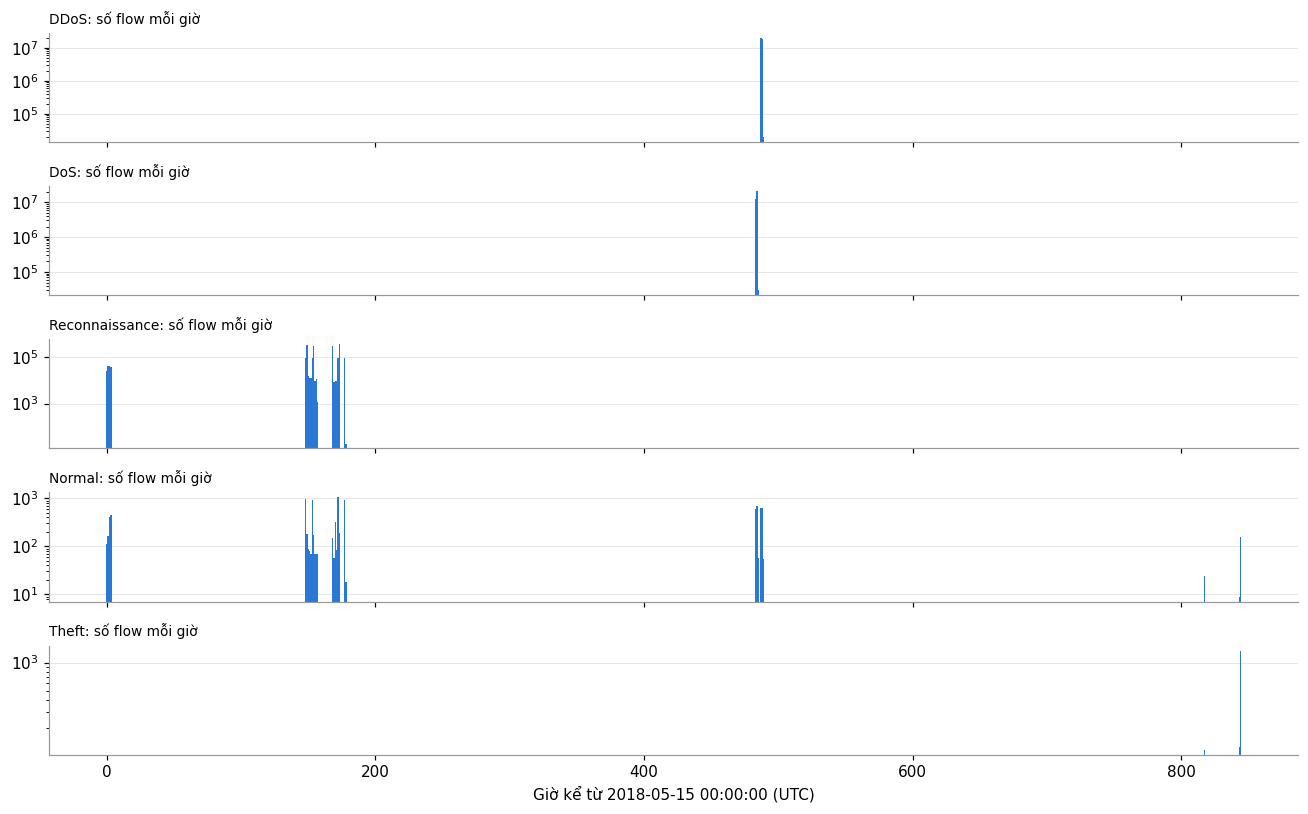

In [6]:
hc = pd.Series(hour_counts).rename_axis(['hour', 'category']).unstack(fill_value=0).sort_index()
t0h = hc.index.min()
cats = cat_df.index.tolist()
fig, axes = plt.subplots(len(cats), 1, figsize=(12, 1.5 * len(cats)), sharex=True)
for ax, c in zip(axes, cats):
    v = hc[c]; v = v[v > 0]
    ax.bar(v.index - t0h, v.values, width=1.0, color=BLUE)
    ax.set_yscale('log'); ax.grid(axis='x', visible=False)
    ax.set_title(f'{c}: số flow mỗi giờ', fontsize=9, loc='left')
axes[-1].set_xlabel(f'Giờ kể từ {pd.to_datetime(t0h * 3600, unit="s")} (UTC)')
fig.tight_layout()
fig.savefig(RESULTS / f'phong_bot_iot_full_timeline_{TODAY}.png', bbox_inches='tight')
plt.show()

### Chấm điểm và phiếu dataset

License, bài báo gốc và mức chính xác lấy theo mục 2.3 của notebook chính (cần đối chiếu nguồn gốc).

In [7]:
CRITERIA = [('graph', 'Khả năng dựng đồ thị', 30), ('coverage', 'Độ phủ tấn công', 20),
            ('iot', 'Tính IoT thực tế', 15), ('balance', 'Cân bằng lớp', 10),
            ('cost', 'Chi phí xử lý', 10), ('compare', 'Khả năng so sánh', 10), ('difficulty', 'Độ khó hợp lý', 5)]
SIZE_GB = sum(f.stat().st_size for f in FILES) / 2**30
SCORES = {
    'graph': (10, f'{len(src_ips)} IP nguồn, {len(dst_ips)} IP đích; tấn công chỉ từ vài IP nội bộ (192.168.100.147–150), nạn nhân ít'),
    'coverage': (12, f"DDoS/DoS hàng chục triệu, Recon {cat_df.so_mau.get('Reconnaissance', 0):,}, Theft {cat_df.so_mau.get('Theft', 0):,}; "
                     'không có nhãn botnet/C&C/backdoor riêng (DDoS do botnet thực hiện nhưng nhãn là DDoS)'),
    'iot': (8, 'Thiết bị IoT mô phỏng (Node-RED) trên máy ảo'),
    'balance': (1, f'Normal chỉ {NORMAL_PCT:.4f}%'),
    'cost': (4, f'{SIZE_GB:.1f} GB CSV, {len(FILES)} file, {N_ROWS:,} dòng (> 5 GB)'),
    'compare': (9, 'Rất phổ biến trong IDS (thường dùng bản 5%), có bản NF cho GNN'),
    'difficulty': (1, 'Mô hình đơn giản đã ≈ 99,9%'),
}
TOTAL = sum(v[0] for v in SCORES.values())
GATES = {'G1': (True, 'Cột IP: saddr, daddr'), 'G2': (True, 'Cột thời gian: stime (giây epoch, độ phân giải µs)'),
         'G3': (True, f'Cột nhãn: category ({len(cat_df)} giá trị), subcategory ({len(sub_df)} giá trị), attack (0/1)'),
         'G4': (len(GROUPS_ATTACK) == 3, f'Nhóm tấn công có mặt: {GROUPS_ATTACK}; thiếu Botnet_Backdoor'),
         'G5': (True, 'Học thuật, bắt buộc trích dẫn Koroniotis et al. (2019) (cần xác minh trang license)'),
         'G6': (True, f'{SIZE_GB:.1f} GB; đọc 6 cột toàn bộ {t_read:.0f}s; xử lý đầy đủ ≈ 15–25 phút trên laptop')}
display(pd.DataFrame([{'tieu_chi': lbl, 'diem': SCORES[k][0], 'toi_da': mx, 'ly_do': SCORES[k][1]} for k, lbl, mx in CRITERIA]
                     + [{'tieu_chi': 'Tổng', 'diem': TOTAL, 'toi_da': 100, 'ly_do': ''}]))
display(pd.DataFrame([{'G': k, 'dat': v[0], 'bang_chung': v[1]} for k, v in GATES.items()]))

def md_table(df):
    out = ['| ' + ' | '.join(map(str, df.columns)) + ' |', '|' + '---|' * len(df.columns)]
    out += ['| ' + ' | '.join(str(v) for v in r) + ' |' for r in df.itertuples(index=False)]
    return '\n'.join(out)

card = [
    '# Phiếu dataset: BoT-IoT (đầy đủ, 74 file)',
    f'Người khảo sát: Phong   Ngày: {TODAY}',
    'Link tải: https://research.unsw.edu.au/projects/bot-iot-dataset (bản dùng: Kaggle `vigneshvenkateswaran/bot-iot`)   '
    'License: học thuật, bắt buộc trích dẫn (UNSW)   Bài báo gốc: Koroniotis et al. (2019), FGCS',
    f'Dung lượng: {SIZE_GB:.1f} GB (`data/BoT-IoT/kaggle_full/data_1..74.csv`)   Số mẫu: {N_ROWS:,}   Thời gian đọc thử: {t_read:.0f}s (6 cột)',
    '', '## Điều kiện bắt buộc', '| # | Đạt? | Bằng chứng |', '|---|---|---|',
    *[f"| {k} | {'Đạt' if v[0] else '**Không**'} | {v[1]} |" for k, v in GATES.items()],
    '', '5 dòng đầu (bằng chứng G1–G3):', '', md_table(head[['pkSeqID', 'stime', 'saddr', 'daddr', 'category', 'subcategory']]),
    '', '## Ánh xạ nhãn', md_table(sub_df),
    '', '## Thống kê',
    f'Số IP nguồn khác nhau: {len(src_ips)}   Số IP đích khác nhau: {len(dst_ips)}',
    f'Tỉ lệ bình thường: {NORMAL_PCT:.4f}%   Lớp nhỏ nhất: {SMALLEST}',
    'Các file được xếp theo loại tấn công (pkSeqID liên tục), không theo thời gian → phải gộp và sắp lại theo `stime`.',
    '', '## Chấm điểm', '| Tiêu chí | Điểm | Lý do |', '|---|---|---|',
    *[f'| {lbl} ({mx}) | {SCORES[k][0]} | {SCORES[k][1]} |' for k, lbl, mx in CRITERIA],
    f'| **Tổng (100)** | **{TOTAL}** | |',
    '', '## Kết luận', 'Nên chọn? Không làm dataset chính (dưới 60 điểm); có thể dùng để kiểm tra tổng quát hóa.',
    'Rủi ro: Normal cực ít (FPR đo trên rất ít node), thiếu nhóm botnet/backdoor, quá dễ, ít IP, dung lượng lớn.',
    '', '_Sinh tự động bởi `notebooks/phong_tuan1_bot_iot_full.ipynb`._',
]
(CARDS / 'bot_iot_full.md').write_text('\n'.join(card) + '\n', encoding='utf-8')
print('Đã ghi dataset_cards/bot_iot_full.md — tổng điểm', TOTAL)

,tieu_chi,diem,toi_da,ly_do
0,Khả năng dựng đồ thị,10,30,"28 IP nguồn, 294 IP đích; tấn công chỉ từ vài ..."
1,Độ phủ tấn công,12,20,"DDoS/DoS hàng chục triệu, Recon 1,821,639, The..."
2,Tính IoT thực tế,8,15,Thiết bị IoT mô phỏng (Node-RED) trên máy ảo
3,Cân bằng lớp,1,10,Normal chỉ 0.0130%
4,Chi phí xử lý,4,10,"14.0 GB CSV, 74 file, 73,370,443 dòng (> 5 GB)"
5,Khả năng so sánh,9,10,"Rất phổ biến trong IDS (thường dùng bản 5%), c..."
6,Độ khó hợp lý,1,5,"Mô hình đơn giản đã ≈ 99,9%"
7,Tổng,45,100,


,G,dat,bang_chung
0,G1,True,"Cột IP: saddr, daddr"
1,G2,True,"Cột thời gian: stime (giây epoch, độ phân giải..."
2,G3,True,"Cột nhãn: category (5 giá trị), subcategory (1..."
3,G4,False,"Nhóm tấn công có mặt: ['DoS_DDoS', 'Truy_cap_t..."
4,G5,True,"Học thuật, bắt buộc trích dẫn Koroniotis et al..."
5,G6,True,14.0 GB; đọc 6 cột toàn bộ 27s; xử lý đầy đủ ≈...


Đã ghi dataset_cards/bot_iot_full.md — tổng điểm 45


## 2. Tuần 1 – Ngày 4–5: làm sạch và dựng đồ thị

### 2.1 Đọc, chuẩn hóa lược đồ, làm sạch

Lược đồ flow chuẩn giống notebook chính. Có 2 điểm khác để tiết kiệm RAM:
- `src`/`dst` là **mã số nguyên** của IP (từ điển `IP_VOCAB`, lưu kèm).
- `proto` và nhãn cũng lưu dạng mã.

Các bước làm sạch:
1. Từng file: bỏ thiếu, vô cực, giá trị âm.
2. Gộp tất cả file, sắp theo `stime` (từng cột một).
3. Bỏ bản ghi trùng lặp mọi cột: chỉ cần so các dòng có cùng `ts`.

In [8]:
IP_VOCAB = np.array(sorted(src_ips | dst_ips), dtype=object)
IP_ID = pd.Index(IP_VOCAB)
PROTO_VOCAB = ['tcp', 'udp', 'icmp', 'ipv6-icmp', 'arp', 'other']
LABEL_VOCAB = cat_df.index.tolist()                                  # nhãn gốc (category)
CLASSES = [g for g in GROUP_ORDER if g in set(cat_df.nhom)]          # Normal luôn là lớp 0
CLASS_ID = {c: i for i, c in enumerate(CLASSES)}
LABEL_TO_Y = np.array([CLASS_ID[GROUP_MAP[l.lower()]] for l in LABEL_VOCAB], dtype=np.int8)
NUM = ['ts', 'bytes_fwd', 'bytes_bwd', 'pkts_fwd', 'pkts_bwd', 'dur']
DTYPES = {'ts': np.float64, 'src': np.int32, 'dst': np.int32, 'sport': np.int32, 'dport': np.int32, 'proto': np.int8,
          'bytes_fwd': np.int64, 'bytes_bwd': np.int64, 'pkts_fwd': np.int32, 'pkts_bwd': np.int32, 'dur': np.float32,
          'f_noreply': bool, 'f_rst': bool, 'f_est': bool, 'label_raw': np.int8, 'y': np.int8}

def _port(s):
    """Cổng dạng số; cổng hex ('0x0303') với ICMP, rỗng với ARP → -1."""
    s = s.astype('string').str.strip()
    is_hex = s.str.startswith('0x', na=False)
    out = pd.to_numeric(s.where(~is_hex), errors='coerce')
    out[is_hex] = s[is_hex].map(lambda v: int(v, 16) if all(c in '0123456789abcdefABCDEF' for c in v[2:]) else np.nan)
    return out.fillna(-1).astype('int64')

def load_file(path):
    """Một file BoT-IoT → lược đồ chuẩn (đã mã hóa) + số dòng bị bỏ ở từng bước."""
    df = read_cols(path, ['stime', 'proto', 'saddr', 'sport', 'daddr', 'dport', 'state', 'dur',
                          'spkts', 'dpkts', 'sbytes', 'dbytes', 'category'])
    state = df['state'].str.strip()
    std = pd.DataFrame({
        'ts': pd.to_numeric(df['stime'], errors='coerce'),
        'src': IP_ID.get_indexer(df['saddr'].str.strip()), 'dst': IP_ID.get_indexer(df['daddr'].str.strip()),
        'sport': _port(df['sport']), 'dport': _port(df['dport']),
        'proto': pd.Categorical(df['proto'].str.strip().str.lower(), categories=PROTO_VOCAB).fillna('other').codes,
        'bytes_fwd': df['sbytes'], 'bytes_bwd': df['dbytes'], 'pkts_fwd': df['spkts'], 'pkts_bwd': df['dpkts'],
        'dur': df['dur'],
        'f_noreply': state.isin(['REQ', 'INT']).to_numpy(), 'f_rst': state.eq('RST').to_numpy(),
        'f_est': state.isin(['CON', 'FIN', 'ACC']).to_numpy(),
        'label_raw': pd.Categorical(df['category'].str.strip(), categories=LABEL_VOCAB).codes,
    })
    n0 = len(std)
    std[NUM] = std[NUM].apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan)
    std = std[std[NUM].notna().all(axis=1) & (std.src >= 0) & (std.dst >= 0) & (std.label_raw >= 0)]
    n1 = len(std)
    std = std[(std[['bytes_fwd', 'bytes_bwd', 'pkts_fwd', 'pkts_bwd', 'dur']] >= 0).all(axis=1)]
    std = std.assign(y=LABEL_TO_Y[std['label_raw'].to_numpy()])
    return std.astype(DTYPES), (n0, n1, len(std))

t0 = time.perf_counter()
parts = {c: [] for c in DTYPES}
counts = np.zeros(3, dtype=np.int64)
for f in FILES:
    std, c = load_file(f)
    counts += c
    for col in DTYPES:
        parts[col].append(std[col].to_numpy())
    del std
print(f'Đọc + chuẩn hóa {len(FILES)} file: {time.perf_counter() - t0:.0f}s')

# Gộp và sắp theo thời gian từng cột một (đỉnh RAM ≈ dữ liệu + 2 cột)
ts_all = np.concatenate(parts.pop('ts'))
order = np.argsort(ts_all, kind='stable')
cols = {'ts': ts_all[order]}; del ts_all
for col in list(parts):
    cols[col] = np.concatenate(parts.pop(col))[order]
del order
flows = pd.DataFrame(cols, copy=False); del cols

# Trùng lặp mọi cột: hai bản ghi trùng phải có cùng ts → chỉ xét các dòng có ts lặp
ts = flows['ts'].to_numpy()
same_ts = np.zeros(len(ts), bool); eq = ts[1:] == ts[:-1]; same_ts[1:] |= eq; same_ts[:-1] |= eq
dup_idx = flows.index[same_ts][flows[same_ts].duplicated().to_numpy()]
flows = flows.drop(index=dup_idx).reset_index(drop=True)
clean_log = pd.DataFrame([('Ban đầu', counts[0]), ('Bỏ thiếu / vô cực / IP rỗng', counts[1]),
                          ('Bỏ giá trị âm', counts[2]), ('Bỏ bản ghi trùng lặp', len(flows))], columns=['buoc', 'so_dong'])
display(clean_log)
print(f'RAM của bảng flow: {flows.memory_usage(deep=True).sum() / 2**30:.2f} GB | lớp: {CLASSES} | {time.perf_counter() - t0:.0f}s')
display(pd.Series(np.bincount(flows['y'], minlength=len(CLASSES)), index=CLASSES, name='so_flow').to_frame())

C:\Users\DELL\AppData\Local\Temp\ipykernel_14396\162106864.py:30: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  'proto': pd.Categorical(df['proto'].str.strip().str.lower(), categories=PROTO_VOCAB).fillna('other').codes,


Đọc + chuẩn hóa 74 file: 188s


,buoc,so_dong
0,Ban đầu,73370443
1,Bỏ thiếu / vô cực / IP rỗng,73370443
2,Bỏ giá trị âm,73370443
3,Bỏ bản ghi trùng lặp,73370443


RAM của bảng flow: 3.96 GB | lớp: ['Normal', 'DoS_DDoS', 'Truy_cap_trai_phep'] | 286s


,so_flow
Normal,9543
DoS_DDoS,71537674
Truy_cap_trai_phep,1823226


In [9]:
# Lưu bản sạch (IP/giao thức/nhãn lưu dạng categorical để file tự đọc được) + từ điển mã
CLEAN_FILE = PROC / 'clean_bot_iot_full.parquet'
t0 = time.perf_counter()
pd.DataFrame({**{c: flows[c] for c in flows.columns if c not in ('src', 'dst', 'proto', 'label_raw')},
              'src': pd.Categorical.from_codes(flows['src'], categories=IP_VOCAB),
              'dst': pd.Categorical.from_codes(flows['dst'], categories=IP_VOCAB),
              'proto': pd.Categorical.from_codes(flows['proto'], categories=PROTO_VOCAB),
              'label_raw': pd.Categorical.from_codes(flows['label_raw'], categories=LABEL_VOCAB)},
             copy=False).to_parquet(CLEAN_FILE, index=False, row_group_size=2_000_000)
(PROC / 'vocab.json').write_text(json.dumps({'ip': IP_VOCAB.tolist(), 'proto': PROTO_VOCAB, 'label_raw': LABEL_VOCAB,
                                             'classes': CLASSES}, ensure_ascii=False), encoding='utf-8')
print(f'{CLEAN_FILE.relative_to(ROOT).as_posix()}: {CLEAN_FILE.stat().st_size / 2**20:.0f} MB ({time.perf_counter() - t0:.0f}s)')

data/processed/bot_iot_full/clean_bot_iot_full.parquet: 543 MB (43s)


### 2.2 Dựng đồ thị (cùng logic với notebook chính)

- **Đặc trưng node:** 18 đặc trưng, mô tả trong `results/phong_features.md`.
- **Quy tắc nhãn node:** đa số nhãn trong các flow IP khởi tạo. Nếu IP không khởi tạo flow nào thì lấy đa số trong các flow IP nhận. Nếu hòa thì chọn lớp có mã lớn hơn.
- **Cửa sổ** `k` phủ `[k·S, k·S+W)` theo giây epoch.

Khác notebook chính: IP và giao thức ở dạng mã. `ips` của từng đồ thị được dịch lại thành chuỗi IP.

In [10]:
FEATURES = ['n_out', 'n_in', 'bytes_sent', 'bytes_recv', 'pkts_sent', 'pkts_recv', 'uniq_dst', 'uniq_dport',
            'uniq_src', 'dur_mean', 'pkt_size_mean', 'noreply_ratio', 'rst_ratio', 'est_ratio', 'tcp_ratio',
            'udp_ratio', 'icmp_ratio', 'iat_mean_out']
LOG_FEATURES = ['n_out', 'n_in', 'bytes_sent', 'bytes_recv', 'pkts_sent', 'pkts_recv', 'uniq_dst',
                'uniq_dport', 'uniq_src', 'dur_mean', 'pkt_size_mean', 'iat_mean_out']
EDGE_FEATURES = ['e_flows', 'e_bytes', 'e_pkts']
P_TCP, P_UDP = PROTO_VOCAB.index('tcp'), PROTO_VOCAB.index('udp')
P_ICMP = [PROTO_VOCAB.index('icmp'), PROTO_VOCAB.index('ipv6-icmp')]

def assign_windows(fl, window_sec, stride_sec):
    assert window_sec % stride_sec == 0, 'WINDOW_SEC phải chia hết cho STRIDE_SEC'
    k_last = np.floor(fl['ts'].to_numpy() / stride_sec).astype(np.int64)
    r = window_sec // stride_sec
    parts = [fl.assign(win=k_last - j) for j in range(r)]
    return parts[0] if r == 1 else pd.concat(parts, ignore_index=True)

def node_edge_tables(fw, window_sec):
    fw = fw[fw['src'] != fw['dst']]
    proto = fw['proto'].to_numpy()
    common = dict(win=fw['win'].to_numpy(), dur=fw['dur'].to_numpy(np.float64),
                  tot_b=(fw['bytes_fwd'] + fw['bytes_bwd']).to_numpy(),
                  tot_p=(fw['pkts_fwd'].astype(np.int64) + fw['pkts_bwd']).to_numpy(),
                  noreply=fw['f_noreply'].to_numpy(), rst=fw['f_rst'].to_numpy(), est=fw['f_est'].to_numpy(),
                  tcp=proto == P_TCP, udp=proto == P_UDP, icmp=np.isin(proto, P_ICMP),
                  y=fw['y'].to_numpy(), ts=fw['ts'].to_numpy())
    out = pd.DataFrame({**common, 'ip': fw['src'].to_numpy(), 'peer': fw['dst'].to_numpy(),
                        'pport': fw['dport'].to_numpy(), 'sent_b': fw['bytes_fwd'].to_numpy(),
                        'recv_b': fw['bytes_bwd'].to_numpy(), 'sent_p': fw['pkts_fwd'].to_numpy(),
                        'recv_p': fw['pkts_bwd'].to_numpy(), 'prio': 0})
    inc = pd.DataFrame({**common, 'ip': fw['dst'].to_numpy(), 'peer': fw['src'].to_numpy(),
                        'pport': fw['sport'].to_numpy(), 'sent_b': fw['bytes_bwd'].to_numpy(),
                        'recv_b': fw['bytes_fwd'].to_numpy(), 'sent_p': fw['pkts_bwd'].to_numpy(),
                        'recv_p': fw['pkts_fwd'].to_numpy(), 'prio': 1})
    long = pd.concat([out, inc], ignore_index=True)
    key = ['win', 'ip']
    nodes = long.groupby(key).agg(
        bytes_sent=('sent_b', 'sum'), bytes_recv=('recv_b', 'sum'),
        pkts_sent=('sent_p', 'sum'), pkts_recv=('recv_p', 'sum'),
        dur_mean=('dur', 'mean'), tot_b=('tot_b', 'sum'), tot_p=('tot_p', 'sum'),
        noreply_ratio=('noreply', 'mean'), rst_ratio=('rst', 'mean'), est_ratio=('est', 'mean'),
        tcp_ratio=('tcp', 'mean'), udp_ratio=('udp', 'mean'), icmp_ratio=('icmp', 'mean'))
    nodes['pkt_size_mean'] = nodes['tot_b'] / nodes['tot_p'].clip(lower=1)
    nodes = nodes.join(out.groupby(key).agg(n_out=('peer', 'size'), uniq_dst=('peer', 'nunique'),
                                            uniq_dport=('pport', 'nunique')))
    nodes = nodes.join(inc.groupby(key).agg(n_in=('peer', 'size'), uniq_src=('peer', 'nunique')))
    o = out.sort_values(key + ['ts'], kind='stable')
    iat = o['ts'].diff().where(o['win'].eq(o['win'].shift()) & o['ip'].eq(o['ip'].shift()))
    nodes = nodes.join(iat.groupby([o['win'], o['ip']]).mean().rename('iat_mean_out'))
    cnt_cols = ['n_out', 'uniq_dst', 'uniq_dport', 'n_in', 'uniq_src']
    nodes[cnt_cols] = nodes[cnt_cols].fillna(0)
    nodes['iat_mean_out'] = nodes['iat_mean_out'].fillna(float(window_sec))
    cnt = long.groupby(key + ['prio', 'y']).size().rename('c').reset_index()
    cnt = cnt.sort_values(key + ['prio', 'c', 'y'], ascending=[True, True, True, False, False], kind='stable')
    nodes['y'] = cnt.drop_duplicates(key).set_index(key)['y']
    nodes = nodes.reset_index().sort_values(key, kind='stable').reset_index(drop=True)
    nodes[LOG_FEATURES] = np.log1p(nodes[LOG_FEATURES].astype('float64'))
    nodes['local'] = nodes.groupby('win').cumcount()
    e = fw.assign(tot_b=common['tot_b'], tot_p=common['tot_p']).groupby(['win', 'src', 'dst']).agg(
        e_flows=('ts', 'size'), e_bytes=('tot_b', 'sum'), e_pkts=('tot_p', 'sum')).reset_index()
    idx = nodes[['win', 'ip', 'local']]
    e = e.merge(idx.rename(columns={'ip': 'src', 'local': 's'}), on=['win', 'src']) \
         .merge(idx.rename(columns={'ip': 'dst', 'local': 'd'}), on=['win', 'dst'])
    e = e.sort_values(['win', 's', 'd'], kind='stable').reset_index(drop=True)
    e[EDGE_FEATURES] = np.log1p(e[EDGE_FEATURES].astype('float64'))
    return nodes[['win', 'ip', 'local', *FEATURES, 'y']], e[['win', 's', 'd', *EDGE_FEATURES]]

def to_pyg(nodes, edges, scaler, stride_sec):
    X = nodes[FEATURES].to_numpy(np.float64)
    X = (scaler.transform(X) if scaler is not None else X).astype(np.float32)
    Y = nodes['y'].to_numpy(np.int64)
    ips = IP_VOCAB[nodes['ip'].to_numpy()]
    wins, starts = np.unique(nodes['win'].to_numpy(), return_index=True)
    ends = np.r_[starts[1:], len(nodes)]
    ew = edges['win'].to_numpy()
    ea, eb = np.searchsorted(ew, wins, 'left'), np.searchsorted(ew, wins, 'right')
    E = edges[['s', 'd']].to_numpy(np.int64)
    EA = edges[EDGE_FEATURES].to_numpy(np.float32)
    graphs = []
    for k, a, b, c, d in zip(wins, starts, ends, ea, eb):
        graphs.append(Data(x=torch.from_numpy(X[a:b].copy()), y=torch.from_numpy(Y[a:b].copy()),
                           edge_index=torch.from_numpy(E[c:d].T.copy()), edge_attr=torch.from_numpy(EA[c:d].copy()),
                           win=int(k), t_start=float(k * stride_sec), ips=list(ips[a:b])))
    return graphs

def build_tables(flows, window_sec, stride_sec, max_flows=CHUNK_FLOWS):
    """Bảng node/cạnh của mọi cửa sổ; mỗi lô gồm các cửa sổ liền nhau với tối đa ~max_flows flow."""
    ts = flows['ts'].to_numpy(); n = len(ts); r = window_sec // stride_sec
    kf = np.floor(ts / stride_sec).astype(np.int64)
    nodes_l, edges_l = [], []
    k0 = int(kf[0]) - (r - 1)
    while True:
        lo = np.searchsorted(ts, k0 * stride_sec, 'left')
        if lo >= n:
            break
        k0 = max(k0, int(kf[lo]) - (r - 1))                       # nhảy qua khoảng trống không có flow
        lo = np.searchsorted(ts, k0 * stride_sec, 'left')
        k1 = max(int(kf[min(lo + max_flows, n) - 1]) + 1, k0 + 1)
        hi = np.searchsorted(ts, (k1 - 1) * stride_sec + window_sec, 'left')
        fw = assign_windows(flows.iloc[lo:hi], window_sec, stride_sec)
        nd, ed = node_edge_tables(fw[(fw['win'] >= k0) & (fw['win'] < k1)], window_sec)
        nodes_l.append(nd); edges_l.append(ed)
        k0 = k1
    return pd.concat(nodes_l, ignore_index=True), pd.concat(edges_l, ignore_index=True)

def time_split(wins, ratios, gap, mode=SPLIT_MODE, blocks=SPLIT_BLOCKS):
    segs = [wins] if mode == 'chronological' else np.array_split(wins, blocks)
    out = {'train': [], 'val': [], 'test': []}
    for i, seg in enumerate(segs):
        n = len(seg)
        a, b = int(n * ratios[0]), int(n * (ratios[0] + ratios[1]))
        out['train'].append(seg[(gap if i else 0):a]); out['val'].append(seg[a + gap:b]); out['test'].append(seg[b + gap:])
    return {p: np.concatenate(v) for p, v in out.items()}

def build_dataset(flows, window_sec, stride_sec):
    nodes, edges = build_tables(flows, window_sec, stride_sec)
    wins = np.unique(nodes['win'].to_numpy())
    split = time_split(wins, SPLIT_RATIO, window_sec // stride_sec - 1)
    scaler = StandardScaler().fit(nodes.loc[nodes['win'].isin(split['train']), FEATURES].to_numpy(np.float64))
    keep = np.concatenate(list(split.values()))
    graphs = to_pyg(nodes[nodes['win'].isin(keep)], edges[edges['win'].isin(keep)], scaler, stride_sec)
    return graphs, split, scaler, nodes

### 2.3 Chia theo thời gian: kiểm tra phân bố lớp trước khi dựng

Tấn công trong BoT-IoT diễn ra theo lịch, mỗi loại vào một khoảng thời gian (xem biểu đồ ở mục 1). Bảng dưới đếm số flow mỗi nhóm trong từng tập, so sánh hai cách chia:
- `chronological`: đúng quy định trong tổng quan, train < val < test.
- `blocked`: phương án đề xuất, chưa dùng nếu Phúc chưa duyệt.

In [11]:
kf = np.floor(flows['ts'].to_numpy() / STRIDE_SEC).astype(np.int64)
all_wins = np.unique(kf)
yv = flows['y'].to_numpy()
cmp = {}
for mode in ('chronological', 'blocked'):
    sp = time_split(all_wins, SPLIT_RATIO, WINDOW_SEC // STRIDE_SEC - 1, mode=mode)
    cmp[mode] = pd.DataFrame({p: np.bincount(yv[np.isin(kf, ws)], minlength=len(CLASSES)) for p, ws in sp.items()},
                             index=CLASSES)
    if mode == 'chronological':
        for p, ws in sp.items():
            print(f'{p:5s}: {pd.to_datetime(ws[0] * STRIDE_SEC, unit="s")} → {pd.to_datetime(ws[-1] * STRIDE_SEC + WINDOW_SEC, unit="s")} ({len(ws):,} cửa sổ)')
split_cmp = pd.concat(cmp, axis=1)
display(split_cmp)
print('Nhóm vắng mặt trong train khi chia chronological:',
      [c for c in CLASSES if split_cmp.loc[c, ('chronological', 'train')] == 0] or 'không',
      f'| SPLIT_MODE đang dùng: {SPLIT_MODE!r}')
del kf, yv

train: 2018-05-15 00:27:10 → 2018-05-22 03:32:50 (8,908 cửa sổ)
val  : 2018-05-22 03:32:50 → 2018-06-04 03:30:30 (1,909 cửa sổ)
test : 2018-06-04 03:30:30 → 2018-06-19 04:17:15 (1,909 cửa sổ)


chronological                      blocked                   
                           train      val      test     train       val     test
Normal                      4442     2701      2400      7487      1196      860
DoS_DDoS                       0  8180152  63357522  57408430  10075874  4053370
Truy_cap_trai_phep       1299156   522483      1587   1074821    370158   378247

Nhóm vắng mặt trong train khi chia chronological: ['DoS_DDoS'] | SPLIT_MODE đang dùng: 'chronological'


### 2.4 Dựng, chuẩn hóa (scaler fit trên train), lưu

In [12]:
t0 = time.perf_counter()
graphs, split_wins, scaler, nodes_raw = build_dataset(flows, WINDOW_SEC, STRIDE_SEC)
print(f'Dựng {len(graphs):,} đồ thị trong {time.perf_counter() - t0:.0f}s')

win_pos = {g.win: i for i, g in enumerate(graphs)}
SPLIT = {}
for part, ws in split_wins.items():
    SPLIT[part] = {'graph_idx': [win_pos[int(w)] for w in ws], 'windows': [int(w) for w in ws],
                   't_start': float(ws[0] * STRIDE_SEC), 't_end': float(ws[-1] * STRIDE_SEC + WINDOW_SEC),
                   't_start_utc': str(pd.to_datetime(ws[0] * STRIDE_SEC, unit='s')),
                   't_end_utc': str(pd.to_datetime(ws[-1] * STRIDE_SEC + WINDOW_SEC, unit='s'))}
GRAPH_FILE = PROC / f'graphs_bot_iot_full_w{WINDOW_SEC}s{STRIDE_SEC}.pt'
split_json = {
    'dataset': 'bot_iot_full', 'source': f'Kaggle {KAGGLE_HANDLE} (data_1..{N_FILES}.csv)',
    'graph_file': GRAPH_FILE.relative_to(ROOT).as_posix(), 'created': TODAY, 'seed': SEED,
    'ts_unit': 'giây', 'ts_note': 'ts = stime (giây epoch)', 'split_mode': SPLIT_MODE,
    'window_sec': WINDOW_SEC, 'stride_sec': STRIDE_SEC, 'ratios': SPLIT_RATIO,
    'gap_windows': WINDOW_SEC // STRIDE_SEC - 1, 'classes': CLASSES, 'features': FEATURES,
    'log1p_features': LOG_FEATURES, 'edge_features': EDGE_FEATURES, 'edge_direction': 'src->dst (có hướng)',
    'node_label_rule': 'đa số nhãn flow IP khởi tạo; nếu không có thì flow IP nhận; hòa → lớp lớn hơn',
    **SPLIT,
}
torch.save(graphs, GRAPH_FILE)
(PROC / 'split.json').write_text(json.dumps(split_json, ensure_ascii=False, indent=1), encoding='utf-8')
with open(PROC / 'scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
for p in (GRAPH_FILE, PROC / 'split.json', PROC / 'scaler.pkl', CLEAN_FILE, PROC / 'vocab.json'):
    print(f'{p.relative_to(ROOT).as_posix():60s} {p.stat().st_size / 2**20:8.2f} MB')
print(pd.DataFrame({k: {c: v for c, v in s.items() if c not in ('graph_idx', 'windows')} | {'n_windows': len(s['windows'])}
                    for k, s in SPLIT.items()}).T.to_string())

Dựng 12,726 đồ thị trong 98s


data/processed/bot_iot_full/graphs_bot_iot_full_w5s5.pt         20.72 MB
data/processed/bot_iot_full/split.json                           0.31 MB
data/processed/bot_iot_full/scaler.pkl                           0.00 MB
data/processed/bot_iot_full/clean_bot_iot_full.parquet         543.20 MB
data/processed/bot_iot_full/vocab.json                           0.01 MB
            t_start         t_end          t_start_utc            t_end_utc n_windows
train  1526344030.0  1526959970.0  2018-05-15 00:27:10  2018-05-22 03:32:50      8908
val    1526959970.0  1528083030.0  2018-05-22 03:32:50  2018-06-04 03:30:30      1909
test   1528083030.0  1529381835.0  2018-06-04 03:30:30  2018-06-19 04:17:15      1909


## 3. Tuần 1 – Ngày 6–7: thống kê, kiểm tra rò rỉ, kiểm tra tái lập

In [13]:
def graph_stats(gs, part):
    nn_ = np.array([g.num_nodes for g in gs]); ne = np.array([g.num_edges for g in gs])
    y = torch.cat([g.y for g in gs]).numpy()
    row = {'tap': part, 'so_do_thi': len(gs), 'node_tb': nn_.mean().round(2), 'node_trung_vi': np.median(nn_),
           'node_max': nn_.max(), 'canh_tb': ne.mean().round(2), 'canh_max': ne.max(), 'tong_node': len(y)}
    for i, c in enumerate(CLASSES):
        row[f'node_{c}'] = int((y == i).sum()); row[f'%_{c}'] = round((y == i).mean() * 100, 3)
    return row

SPLIT_GRAPHS = {p: [graphs[i] for i in SPLIT[p]['graph_idx']] for p in ('train', 'val', 'test')}
stats_df = pd.DataFrame([graph_stats(gs, p) for p, gs in SPLIT_GRAPHS.items()] + [graph_stats(graphs, 'tat_ca')])
stats_df.insert(1, 'window_sec', WINDOW_SEC); stats_df.insert(2, 'stride_sec', STRIDE_SEC)
stats_df.to_csv(RESULTS / 'phong_bot_iot_full_graph_stats.csv', index=False)
stats_df

,tap,window_sec,stride_sec,so_do_thi,node_tb,node_trung_vi,node_max,canh_tb,canh_max,tong_node,node_Normal,%_Normal,node_DoS_DDoS,%_DoS_DDoS,node_Truy_cap_trai_phep,%_Truy_cap_trai_phep
0,train,5,5,8908,4.88,5.0,39,4.69,38,43441,3996,9.199,0,0.000,39445,90.801
1,val,5,5,1909,4.94,5.0,36,4.49,33,9435,2074,21.982,1260,13.355,6101,64.663
2,test,5,5,1909,4.72,4.0,24,3.95,28,9012,1919,21.294,6464,71.727,629,6.980
3,tat_ca,5,5,12726,4.86,5.0,39,4.55,38,61888,7989,12.909,7724,12.481,46175,74.611


In [14]:
checks = []
w = {p: set(SPLIT[p]['windows']) for p in SPLIT}
checks.append(('Không cửa sổ trùng giữa các tập', not (w['train'] & w['val'] or w['train'] & w['test'] or w['val'] & w['test'])))
if SPLIT_MODE == 'chronological':
    checks.append(('Thời gian: train kết thúc ≤ val bắt đầu', SPLIT['train']['t_end'] <= SPLIT['val']['t_start']))
    checks.append(('Thời gian: val kết thúc ≤ test bắt đầu', SPLIT['val']['t_end'] <= SPLIT['test']['t_start']))
# mỗi flow chỉ thuộc cửa sổ của một tập (một flow có thể thuộc W/S cửa sổ)
kf = np.floor(flows['ts'].to_numpy() / STRIDE_SEC).astype(np.int64)
seen = np.full(len(kf), -1, np.int8); conflict = 0
for j in range(WINDOW_SEC // STRIDE_SEC):
    for pi, p in enumerate(('train', 'val', 'test')):
        m = np.isin(kf - j, split_wins[p])
        conflict += int((m & (seen >= 0) & (seen != pi)).sum()); seen[m] = pi
checks.append(('Không flow/timestamp nào thuộc 2 tập', conflict == 0))
checks.append(('Scaler chỉ fit trên train (số mẫu = số node train)',
               scaler.n_samples_seen_ == stats_df.loc[stats_df.tap == 'train', 'tong_node'].item()))
display(pd.DataFrame(checks, columns=['kiem_tra', 'dat']))
del kf, seen

ips = {p: set(ip for g in gs for ip in g.ips) for p, gs in SPLIT_GRAPHS.items()}
print('Số IP mỗi tập:', {p: len(s) for p, s in ips.items()})
print('IP chung train∩test:', len(ips['train'] & ips['test']), '| chỉ có ở test:', sorted(ips['test'] - ips['train'])[:10])
print('→ IP trùng giữa các tập là bình thường (cùng thiết bị); IP không phải đặc trưng nên không rò rỉ nhãn.')

,kiem_tra,dat
0,Không cửa sổ trùng giữa các tập,True
1,Thời gian: train kết thúc ≤ val bắt đầu,True
2,Thời gian: val kết thúc ≤ test bắt đầu,True
3,Không flow/timestamp nào thuộc 2 tập,True
4,Scaler chỉ fit trên train (số mẫu = số node tr...,True


Số IP mỗi tập: {'train': 232, 'val': 164, 'test': 102}
IP chung train∩test: 72 | chỉ có ở test: ['0.0.0.0', '0.0.0.1', '00:00:00:00:00:00', '00:00:00:00:4f:b7', '116.206.80.123', '116.206.83.243', '118.215.114.65', '13.54.166.67', '172.217.25.138', '203.5.76.24']
→ IP trùng giữa các tập là bình thường (cùng thiết bị); IP không phải đặc trưng nên không rò rỉ nhãn.


In [15]:
# Tái lập: đọc lại clean parquet, dựng lại toàn bộ, so hash (đọc lại 74 CSV gốc mất thời gian nên dùng bản sạch đã lưu)
def fingerprint(gs):
    h = hashlib.sha256()
    for g in gs:
        for t in (g.x, g.y, g.edge_index, g.edge_attr):
            h.update(t.numpy().tobytes())
        h.update(('|'.join(g.ips) + str(g.win)).encode())
    return h.hexdigest()

fp1 = fingerprint(graphs)
del nodes_raw
t0 = time.perf_counter()
cl = pd.read_parquet(CLEAN_FILE)
for c, vocab in (('src', IP_VOCAB), ('dst', IP_VOCAB), ('proto', PROTO_VOCAB), ('label_raw', LABEL_VOCAB)):
    cat = cl[c].cat                                   # thứ tự category đọc từ parquet có thể khác từ điển gốc
    cl[c] = pd.Index(vocab).get_indexer(cat.categories)[cat.codes].astype(DTYPES[c])
same_flows = all(np.array_equal(cl[c].to_numpy(), flows[c].to_numpy()) for c in flows.columns)
del flows
graphs2, split2, _, _ = build_dataset(cl, WINDOW_SEC, STRIDE_SEC)
fp2 = fingerprint(graphs2)
print(f'Parquet đọc lại khớp bảng flow: {same_flows} | hash lần 1 {fp1[:16]} | lần 2 {fp2[:16]} | giống nhau: {fp1 == fp2}'
      f" | split giống nhau: {all(np.array_equal(split_wins[p], split2[p]) for p in split2)} ({time.perf_counter() - t0:.0f}s)")
del cl, graphs2
loaded = torch.load(GRAPH_FILE, weights_only=False)
print('File .pt đọc lại khớp:', fingerprint(loaded) == fp1)
del loaded

Parquet đọc lại khớp bảng flow: True | hash lần 1 3cc75cffb8de3351 | lần 2 3cc75cffb8de3351 | giống nhau: True | split giống nhau: True (100s)


File .pt đọc lại khớp: True


## 4. Tổng kết

In [16]:
outputs = [CARDS / 'bot_iot_full.md', CLEAN_FILE, PROC / 'vocab.json', GRAPH_FILE, PROC / 'split.json', PROC / 'scaler.pkl',
           RESULTS / 'phong_bot_iot_full_graph_stats.csv', RESULTS / f'phong_bot_iot_full_timeline_{TODAY}.png']
pd.DataFrame([{'file': p.relative_to(ROOT).as_posix(), 'MB': round(p.stat().st_size / 2**20, 2)} for p in outputs])

,file,MB
0,dataset_cards/bot_iot_full.md,0.00
1,data/processed/bot_iot_full/clean_bot_iot_full...,543.20
2,data/processed/bot_iot_full/vocab.json,0.01
3,data/processed/bot_iot_full/graphs_bot_iot_ful...,20.72
4,data/processed/bot_iot_full/split.json,0.31
5,data/processed/bot_iot_full/scaler.pkl,0.00
6,results/phong_bot_iot_full_graph_stats.csv,0.00
7,results/phong_bot_iot_full_timeline_2026-10-23...,0.03


**Ghi chú cho buổi họp:**

- BoT-IoT đầy đủ **có timestamp thật** (`stime`) nên dựng đúng cửa sổ 5 giây như đề, khác NF-ToN-IoT-v2 phải dùng thứ tự dòng.
- Hạn chế (chi tiết trong phiếu `dataset_cards/bot_iot_full.md`):
  - Normal cực ít, nên FPR được đo trên rất ít node.
  - Không có nhóm Botnet_Backdoor.
  - Tấn công chỉ từ vài IP.
  - Rất dễ: các bài báo đạt ≈ 99,9%.
- Chia theo thời gian toàn cục có thể làm một số loại tấn công chỉ nằm ở một tập (bảng mục 2.3). Đổi `SPLIT_MODE` cần Phúc duyệt.
- Đọc đồ thị: `torch.load('data/processed/bot_iot_full/graphs_bot_iot_full_w5s5.pt', weights_only=False)`. Dùng kèm `split.json` và `scaler.pkl` **trong cùng thư mục** `data/processed/bot_iot_full/`.